# CPE 486/586 — Homework 5
## SVM, PCA, Classification, and Neural Network

**Name:** Md. Aslam Hossain  
**UAH email:** mh0708@uah.edu \
**Package keyword:** tornadochildd  
**GitHub Account:** https://github.com/tornadochilddgh \
**GitHub Repository:** https://github.com/tornadochilddgh/tornadochildd \
**PyPI Release:** \
**Commit Hash:** 

## Q1.

The hyperplanes $\mathbf{w}^{\top}\mathbf{x}=52$ and
$\mathbf{w}^{\top}\mathbf{x}=64$ have the same normal vector $\mathbf{w}$,
so they are parallel. Their perpendicular distance is

$$
d = \frac{|64-52|}{\|\mathbf{w}\|_2}
  = \boxed{\frac{12}{\|\mathbf{w}\|_2}}.
$$

Since the magnitude of $\mathbf{w}$ is unknown, the distance cannot be
evaluated numerically.

## Q2.

I would use a soft-margin SVM and try a smaller value of $C$. If the model
tries too hard to classify every training point correctly, even one noisy
point can affect where it places the boundary. With a smaller $C$, the model
can accept a few mistakes and choose a wider margin. This can help it
classify new data more accurately.

To choose $C$, I would try a few values and use the one that gives the
best average accuracy in cross-validation.

## Q3.

I started with the given centroids $C_1=(1,1)$ and $C_2=(5,5)$.

**Step 1. Assign each point to the nearest centroid**

I compared squared Euclidean distances because taking the square root
does not change which centroid is closer. For example, for $(1,2)$,

$$
d_1^2=(1-1)^2+(2-1)^2=1, \qquad
d_2^2=(1-5)^2+(2-5)^2=25.
$$

So I assigned $(1,2)$ to Cluster 1. Applying the same calculation to
the remaining points gives the following assignments.

| Point | Squared distance to $C_1$ | Squared distance to $C_2$ | Assigned cluster |
|---|---:|---:|---|
| $(1,2)$ | 1 | 25 | 1 |
| $(2,1)$ | 1 | 25 | 1 |
| $(4,5)$ | 25 | 1 | 2 |
| $(5,4)$ | 25 | 1 | 2 |

**Step 2. Update the centroids**

I averaged the coordinates of the two points in each cluster.

$$
C_1^{\text{new}}
=\left(\frac{1+2}{2},\frac{2+1}{2}\right)
=\boxed{(1.5,1.5)}
$$

$$
C_2^{\text{new}}
=\left(\frac{4+5}{2},\frac{5+4}{2}\right)
=\boxed{(4.5,4.5)}
$$

## Q4.

I would use K-means to group similar data points. For each point, I would
calculate its distance from its assigned centroid. If that distance is
unusually large compared with the distances of other points in the same
cluster, I would flag it as a possible anomaly.

For example, if most temperature readings from a sensor cluster around
25°C, an isolated reading of 80°C would be worth checking. It could
indicate a sensor error or a real change in temperature.

## Q5.

First, I multiplied each input by its weight and added the bias to find
the weighted sum $z$.

$$
\begin{aligned}
z &= w_1x_1 + w_2x_2 + w_3x_3 + b \\
  &= (0.6)(0.5) + (-0.3)(0.8) + (0.4)(0.2) + 0.1 \\
  &= 0.30 - 0.24 + 0.08 + 0.10 \\
  &= 0.24.
\end{aligned}
$$

Then I applied ReLU. Since $z$ is positive, ReLU returns the same value,
so the neuron’s output is

$$
a = \max(0,z) = \max(0,0.24) = \boxed{0.24}.
$$

## Q6.

### Part 1. Forward propagation through the hidden layer

For each hidden neuron, I multiplied the two inputs by their corresponding
weights and added the results. Since the bias is zero, the weighted sum
and sigmoid activation are

$$
z = w_1x_1 + w_2x_2,
\qquad
a = \sigma(z) = \frac{1}{1+e^{-z}}.
$$

**Training sample 1** has inputs $(x_1,x_2)=(2,4)$.

| Hidden neuron | Weighted sum | Sigmoid activation |
|---|---|---|
| 1 | $z_1^{[1]}=(0.1)(2)+(0.3)(4)=1.4$ | $a_1^{[1]}=\sigma(1.4)\approx 0.802184$ |
| 2 | $z_2^{[1]}=(0.2)(2)+(0.4)(4)=2.0$ | $a_2^{[1]}=\sigma(2.0)\approx 0.880797$ |
| 3 | $z_3^{[1]}=(0.1)(2)+(0.5)(4)=2.2$ | $a_3^{[1]}=\sigma(2.2)\approx 0.900250$ |

**Training sample 2** has inputs $(x_1,x_2)=(4,5)$. I used the same
weights and repeated the calculation with these inputs.

| Hidden neuron | Weighted sum | Sigmoid activation |
|---|---|---|
| 1 | $z_1^{[1]}=(0.1)(4)+(0.3)(5)=1.9$ | $a_1^{[1]}=\sigma(1.9)\approx 0.869892$ |
| 2 | $z_2^{[1]}=(0.2)(4)+(0.4)(5)=2.8$ | $a_2^{[1]}=\sigma(2.8)\approx 0.942676$ |
| 3 | $z_3^{[1]}=(0.1)(4)+(0.5)(5)=2.9$ | $a_3^{[1]}=\sigma(2.9)\approx 0.947846$ |

### Part 2. Forward propagation through the output layer

I used the output weights $W_1^{[2]}=[0.1,\,0.2,\,0.1]$ for both samples.
Since the output bias is zero, the weighted sum is

$$
z_1^{[2]} = 0.1a_1^{[1]} + 0.2a_2^{[1]} + 0.1a_3^{[1]}.
$$

**Training sample 1.** Using the activations I found for $(2,4)$,

$$
\begin{aligned}
z_1^{[2]} &\approx 0.1(0.802184)+0.2(0.880797)+0.1(0.900250) \\
          &\approx 0.346403.
\end{aligned}
$$

After applying sigmoid, I obtained

$$
\hat{y}^{(1)} = a_1^{[2]} \approx \frac{1}{1+e^{-0.346403}}
\approx \boxed{0.5857}.
$$

**Training sample 2.** Using the activations I found for $(4,5)$,

$$
\begin{aligned}
z_1^{[2]} &\approx 0.1(0.869892)+0.2(0.942676)+0.1(0.947846) \\
          &\approx 0.370309.
\end{aligned}
$$

After applying sigmoid, I obtained

$$
\hat{y}^{(2)} = a_1^{[2]} \approx \frac{1}{1+e^{-0.370309}}
\approx \boxed{0.5915}.
$$

### Part 3. Average loss for both training samples

I used the labels as given in the question and calculated the loss for
each sample before taking the average. The loss for one sample is

$$
\ell(y,\hat y)=-\left[y\ln(\hat y)+(1-y)\ln(1-\hat y)\right].
$$

For the first sample, $y^{(1)}=-1$ and $\hat y^{(1)}\approx 0.585745$.
Since $1-(-1)=2$, I obtained

$$
\ell_1
\approx -\left[(-1)\ln(0.585745)+2\ln(1-0.585745)\right]
\approx 1.227676.
$$

For the second sample, $y^{(2)}=1$ and $\hat y^{(2)}\approx 0.591534$.
Here, $1-y^{(2)}=0$, so only the first term contributes:

$$
\ell_2 \approx -\ln(0.591534)\approx 0.525037.
$$

Using the unrounded values, the average loss from the formula as written is

$$
L=\frac{\ell_1+\ell_2}{2}\approx\boxed{0.876356}.
$$

Standard binary cross-entropy uses labels 0 and 1. If I encode the first
label as 0, its loss becomes $-\ln(1-0.585745)\approx 0.881274$, and
the average loss under that encoding is $0.703155$.

### Part 4. Backpropagation and update of the output weights

I used the labels $y^{(1)}=-1$ and $y^{(2)}=1$ as printed in the
question, consistent with my main calculation in Part 3.

**Step 1. Find the gradient for one output weight**

Let $w_j$ be the weight connecting hidden neuron $j$ to the output
neuron, and let $a_j^{[1]}$ be that hidden neuron's activation. Using
the chain rule for one sample, I obtained

$$
\begin{aligned}
\frac{\partial \ell}{\partial w_j}
&= \frac{\partial \ell}{\partial \hat y}
   \frac{\partial \hat y}{\partial z_1^{[2]}}
   \frac{\partial z_1^{[2]}}{\partial w_j} \\
&= \left(-\frac{y}{\hat y}+\frac{1-y}{1-\hat y}\right)
   \hat y(1-\hat y)\,a_j^{[1]} \\
&= (\hat y-y)\,a_j^{[1]}.
\end{aligned}
$$

**Step 2. Calculate the gradient for each sample**

For sample 1, $\hat y^{(1)}-y^{(1)}\approx 0.585745-(-1)=1.585745$.
I multiplied this value by the three hidden activations from Part 1.

$$
\begin{aligned}
g^{(1)}
&\approx 1.585745[0.802184,\;0.880797,\;0.900250] \\
&\approx [1.272059,\;1.396720,\;1.427566].
\end{aligned}
$$

For sample 2, $\hat y^{(2)}-y^{(2)}\approx 0.591534-1=-0.408466$.
Using the hidden activations for this sample, I obtained

$$
\begin{aligned}
g^{(2)}
&\approx -0.408466[0.869892,\;0.942676,\;0.947846] \\
&\approx [-0.355321,\;-0.385051,\;-0.387163].
\end{aligned}
$$

**Step 3. Average the gradients and update the weights**

I averaged the two gradients component by component.

$$
\bar g=\frac{g^{(1)}+g^{(2)}}{2}
\approx [0.458369,\;0.505834,\;0.520201].
$$

Starting from $W_1^{[2]}=[0.1,\,0.2,\,0.1]$ and using the given
learning rate $\eta=0.05$, my updated output weights after one epoch are

$$
\begin{aligned}
W_{1,\mathrm{new}}^{[2]}
&= W_1^{[2]}-\eta\bar g \\
&\approx [0.1,\;0.2,\;0.1]
-0.05[0.458369,\;0.505834,\;0.520201] \\
&\approx \boxed{[0.077082,\;0.174708,\;0.073990]}.
\end{aligned}
$$

## Q7.

Dropout is a technique that helps reduce overfitting in a neural network.
For example, if I set the dropout rate to 0.2, each hidden activation
in that layer has a 20% chance of being set to zero during a training
pass. On the next pass, a different set of activations may be dropped.

This helps because the network cannot always rely on the same few neurons
to make a prediction. It learns to use information from several neurons,
which can help it perform better on new data. When I use the trained
model for prediction, I turn dropout off so all neurons can contribute.

## Q8.

I used PCA to see how much of the variation in the eight diabetes features
I could retain using only two or three components. I kept `Outcome` separate
and used it to color the plots. Before applying PCA, I standardized the
features because measurements such as glucose, BMI, and age use different
units.

In [13]:
import json
from urllib.request import urlopen

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Get the CSV download URL from the folder linked in the assignment.
folder_url = (
    "https://api.github.com/repos/rahulbhadani/Datasets/"
    "contents/Diabetes?ref=master"
)

with urlopen(folder_url) as response:
    files = json.load(response)

csv_files = [
    file for file in files
    if file["type"] == "file" and file["name"].lower().endswith(".csv")
]

if len(csv_files) != 1:
    names = [file["name"] for file in csv_files]
    raise ValueError(f"Expected one CSV in the Diabetes folder. Found: {names}")

dataset_url = csv_files[0]["download_url"]
diabetes = pd.read_csv(dataset_url)

# Outcome is the class label. Only the input features are used for PCA.
diabetes_features = diabetes.drop(columns="Outcome")
diabetes_outcome = diabetes["Outcome"]

scaler = StandardScaler()
scaled_features = scaler.fit_transform(diabetes_features)

pca_2d = PCA(n_components=2)
scores_2d = pca_2d.fit_transform(scaled_features)
variance_2d = 100 * pca_2d.explained_variance_ratio_

print(f"Dataset: {dataset_url}")
print(f"Samples: {len(diabetes)} | Input features: {diabetes_features.shape[1]}")
print(f"PC1 explains {variance_2d[0]:.2f}% of the total variance.")
print(f"PC2 explains {variance_2d[1]:.2f}% of the total variance.")
print(f"Together, PC1 and PC2 explain {variance_2d.sum():.2f}%.")

Dataset: https://raw.githubusercontent.com/rahulbhadani/Datasets/master/Diabetes/diabetes.csv
Samples: 768 | Input features: 8
PC1 explains 26.18% of the total variance.
PC2 explains 21.64% of the total variance.
Together, PC1 and PC2 explain 47.82%.


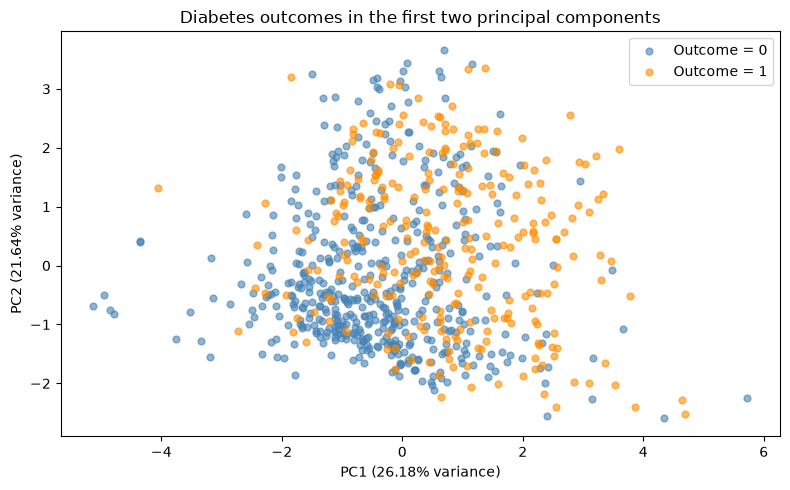

In [14]:
class_colors = {0: "steelblue", 1: "darkorange"}

fig, ax = plt.subplots(figsize=(8, 5))

for outcome, color in class_colors.items():
    mask = diabetes_outcome.to_numpy() == outcome
    ax.scatter(
        scores_2d[mask, 0],
        scores_2d[mask, 1],
        color=color,
        label=f"Outcome = {outcome}",
        alpha=0.60,
        s=24,
    )

ax.set_xlabel(f"PC1 ({variance_2d[0]:.2f}% variance)")
ax.set_ylabel(f"PC2 ({variance_2d[1]:.2f}% variance)")
ax.set_title("Diabetes outcomes in the first two principal components")
ax.legend()
fig.tight_layout()
plt.show()

### Part 2. Interpretation of the 2D plot

Each point represents one sample. The two colors overlap across much of
the plot. Some regions contain more points from one class, but I cannot
draw a clear boundary between outcomes 0 and 1 using PC1 and PC2 alone.

In [15]:
pca_3d = PCA(n_components=3)
scores_3d = pca_3d.fit_transform(scaled_features)
variance_3d = 100 * pca_3d.explained_variance_ratio_

for component, percentage in enumerate(variance_3d, start=1):
    print(f"PC{component} explains {percentage:.2f}% of the total variance.")

print(f"\nTwo-component total:   {variance_2d.sum():.2f}%")
print(f"Three-component total: {variance_3d.sum():.2f}%")
print(f"Adding PC3 retains {variance_3d[2]:.2f} additional percentage points.")

PC1 explains 26.18% of the total variance.
PC2 explains 21.64% of the total variance.
PC3 explains 12.87% of the total variance.

Two-component total:   47.82%
Three-component total: 60.69%
Adding PC3 retains 12.87 additional percentage points.


### Part 3. Contribution of the third component

PC3 captures variation in a direction perpendicular to both PC1 and PC2.
Its individual variance percentage is therefore the amount added to the
two-component total. This means the three-component representation keeps
more information about the original features. Whether that extra information
helps distinguish the outcomes can be checked in the 3D plot.

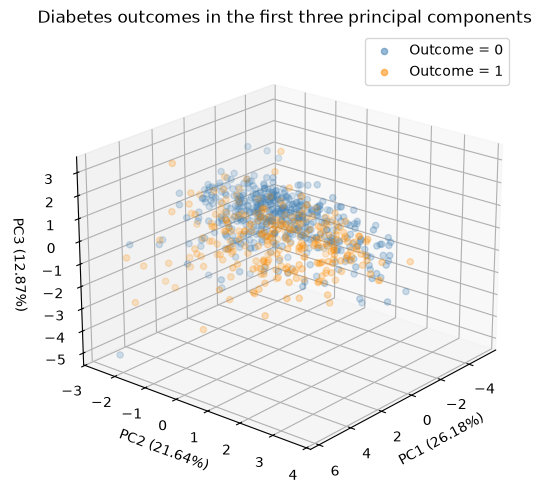

In [16]:
fig = plt.figure(figsize=(9, 6))
ax = fig.add_subplot(111, projection="3d")

for outcome, color in class_colors.items():
    mask = diabetes_outcome.to_numpy() == outcome
    ax.scatter(
        scores_3d[mask, 0],
        scores_3d[mask, 1],
        scores_3d[mask, 2],
        color=color,
        label=f"Outcome = {outcome}",
        alpha=0.55,
        s=20,
    )

ax.set_xlabel(f"PC1 ({variance_3d[0]:.2f}%)")
ax.set_ylabel(f"PC2 ({variance_3d[1]:.2f}%)")
ax.set_zlabel(f"PC3 ({variance_3d[2]:.2f}%)")
ax.set_title("Diabetes outcomes in the first three principal components")
ax.view_init(elev=22, azim=40)
ax.legend()
plt.show()

### Part 4. Comparison of the 2D and 3D plots

Adding PC3 spreads out some samples that appeared close together in the
2D plot. However, the two colors still overlap, so the third component
does not give a clear visual separation between the outcomes. This makes
sense because PCA selects directions that capture variation in the input
features without using the outcome labels.

## Q9. 

### Part 1. Generate and visualize the circles dataset

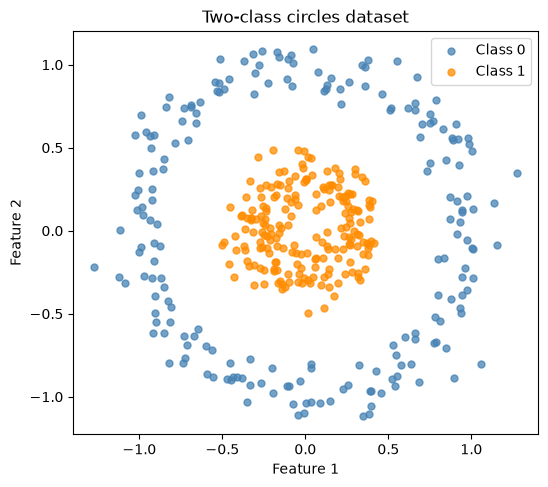

In [17]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles

# Use the parameters given in the assignment.
X_circles, y_circles = make_circles(
    n_samples=400, noise=0.1, factor=0.3, random_state=1
)

fig, ax = plt.subplots(figsize=(6, 6))

for label, color in [(0, "steelblue"), (1, "darkorange")]:
    points = X_circles[y_circles == label]
    ax.scatter(points[:, 0], points[:, 1], s=25, alpha=0.75,
               color=color, label=f"Class {label}")

ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")
ax.set_title("Two-class circles dataset")
ax.set_aspect("equal")
ax.legend()
plt.show()

Class 1 forms an inner ring, and Class 0 forms an outer ring around it.
I expect a linear SVM to perform poorly because its decision boundary is
a straight line. If I draw a line through the center, both sides contain
points from both classes. Moving the line toward an edge can isolate part
of the outer ring, but the rest of that ring still shares a side with the
inner ring. A circular boundary fits this pattern better.

### Part 2. Linear SVM decision boundary and accuracy

Correct predictions: 269 out of 400
Training accuracy: 67.25%


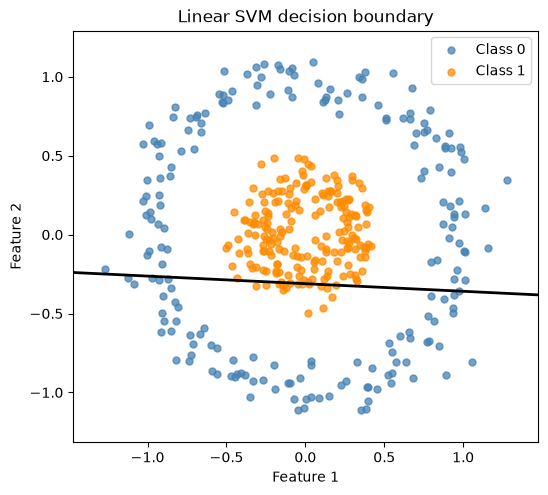

In [18]:
import numpy as np
from sklearn.svm import SVC

def plot_svm_boundary(model, X, y, ax):
    x_grid = np.linspace(X[:, 0].min() - 0.2, X[:, 0].max() + 0.2, 250)
    y_grid = np.linspace(X[:, 1].min() - 0.2, X[:, 1].max() + 0.2, 250)
    xx, yy = np.meshgrid(x_grid, y_grid)

    grid_points = np.column_stack((xx.ravel(), yy.ravel()))
    scores = model.decision_function(grid_points).reshape(xx.shape)

    # The decision boundary is where the SVM score equals zero.
    ax.contour(xx, yy, scores, levels=[0], colors="black", linewidths=2)

    for label, color in [(0, "steelblue"), (1, "darkorange")]:
        points = X[y == label]
        ax.scatter(points[:, 0], points[:, 1], s=25, alpha=0.75,
                   color=color, label=f"Class {label}")

    ax.set(xlabel="Feature 1", ylabel="Feature 2", aspect="equal")
    ax.legend()


linear_svm = SVC(kernel="linear", C=1.0)
linear_svm.fit(X_circles, y_circles)

predictions = linear_svm.predict(X_circles)
correct = np.count_nonzero(predictions == y_circles)
print(f"Correct predictions: {correct} out of {len(y_circles)}")
print(f"Training accuracy: {correct / len(y_circles):.2%}")

fig, ax = plt.subplots(figsize=(6, 6))
plot_svm_boundary(linear_svm, X_circles, y_circles, ax)
ax.set_title("Linear SVM decision boundary")
plt.show()

The linear SVM correctly classified 269 out of 400 points, giving a
training accuracy of 67.25%. In the plot, the straight boundary cuts
across the outer ring. It separates one section of that ring, but many
outer-ring points are still on the same side as the inner ring. This
supports my prediction from Part 1 that a straight line cannot fully
separate these two classes.

### Part 3. RBF kernel SVM decision boundary and accuracy

Correct predictions: 400 out of 400
Training accuracy: 100.00%


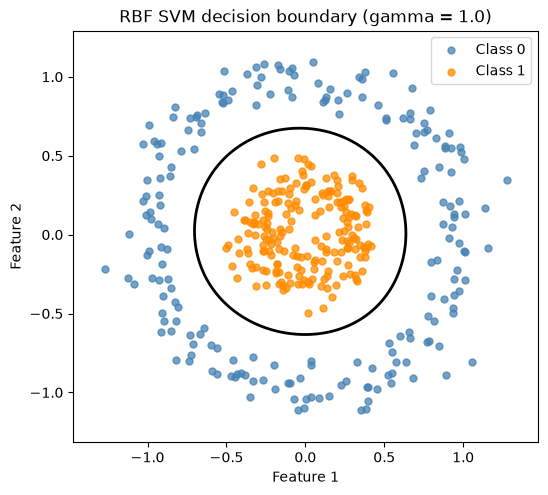

In [19]:
rbf_svm = SVC(kernel="rbf", gamma=1.0, C=1.0)
rbf_svm.fit(X_circles, y_circles)

rbf_predictions = rbf_svm.predict(X_circles)
rbf_correct = np.count_nonzero(rbf_predictions == y_circles)

print(f"Correct predictions: {rbf_correct} out of {len(y_circles)}")
print(f"Training accuracy: {rbf_correct / len(y_circles):.2%}")

fig, ax = plt.subplots(figsize=(6, 6))
plot_svm_boundary(rbf_svm, X_circles, y_circles, ax)
ax.set_title("RBF SVM decision boundary (gamma = 1.0)")
plt.show()

With the RBF kernel, I obtained 100% training accuracy. The decision
boundary forms a closed curve around the inner ring, placing all 400
training points on the correct side. The RBF kernel gives nearby points
higher similarity scores, which allows the SVM to form a curved boundary
in the original two-dimensional plot. This shape fits the gap between
the rings much better than the straight line from Part 2.

### Part 4. Effect of gamma on the RBF decision boundary

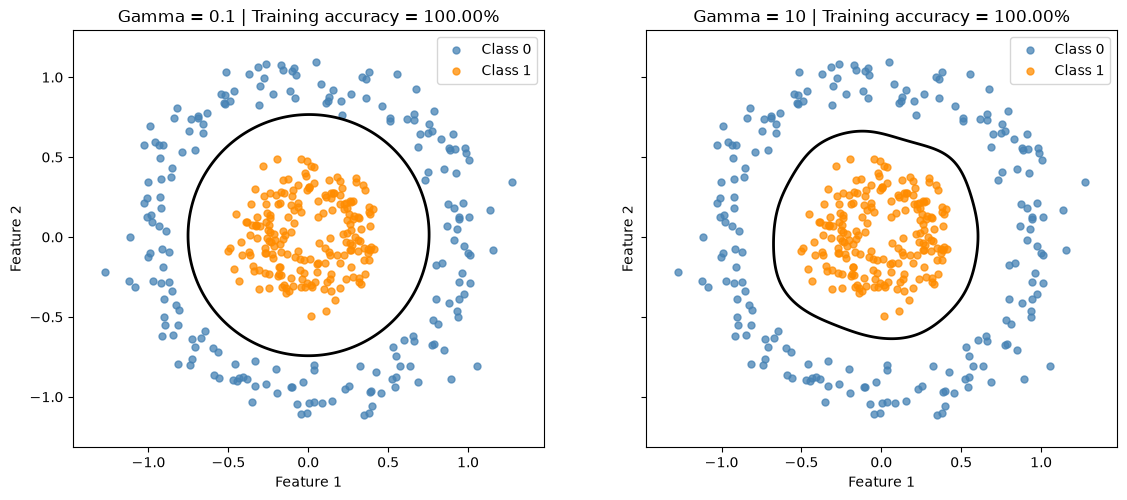

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

for gamma, ax in zip([0.1, 10], axes):
    model = SVC(kernel="rbf", gamma=gamma, C=1.0)
    model.fit(X_circles, y_circles)

    accuracy = model.score(X_circles, y_circles)
    plot_svm_boundary(model, X_circles, y_circles, ax)
    ax.set_title(f"Gamma = {gamma} | Training accuracy = {accuracy:.2%}")

fig.tight_layout()
plt.show()

Both models gave me 100% training accuracy, but their boundaries have
different shapes. With gamma = 0.1, each training point influences a
wider area, producing a smoother curve around the inner ring. If gamma
is too small, the boundary can become too simple to follow the pattern.
That is underfitting.

With gamma = 10, each point influences a smaller area, so the boundary
can bend more in response to nearby points. If it starts following random
noise in the training data, it may perform worse on new samples. That
is overfitting. In this example, both settings separated the training
points perfectly, so I would need held-out data to tell whether the more
flexible boundary actually generalizes worse.

## Q10. 

I generated 500 samples forming two noisy half-moons and applied K-means
with two clusters. I used only the two input features to fit the model.
I kept the original moon labels so I could check how closely the clusters
matched the two moons.

Adjusted Rand Index:     0.2773
V-measure:               0.2122
Silhouette Score:        0.4689
Calinski-Harabasz Index: 664.0788


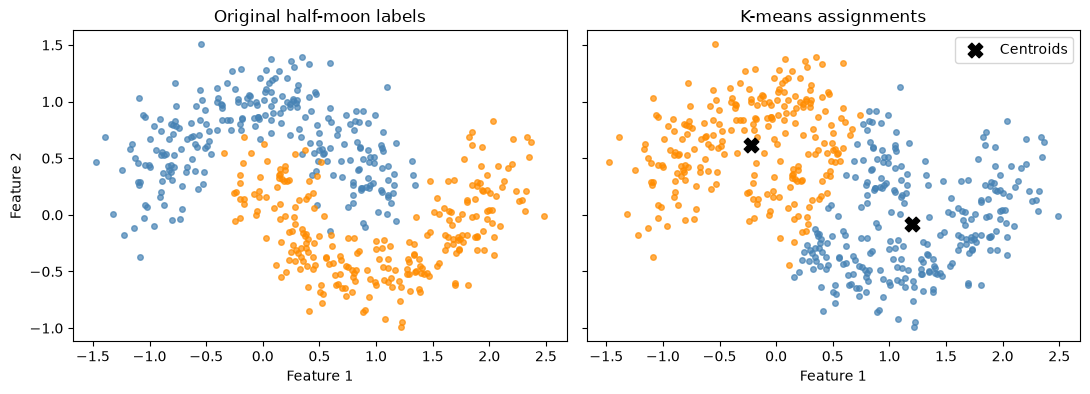

In [21]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import make_moons
from sklearn.metrics import (
    adjusted_rand_score,
    calinski_harabasz_score,
    silhouette_score,
    v_measure_score,
)

X_moons, y_moons = make_moons(n_samples=500, noise=0.2, random_state=42)

kmeans = KMeans(n_clusters=2, n_init=20, random_state=42)
cluster_labels = kmeans.fit_predict(X_moons)

# Compare the assigned clusters with the original moon labels.
print(f"Adjusted Rand Index:     {adjusted_rand_score(y_moons, cluster_labels):.4f}")
print(f"V-measure:               {v_measure_score(y_moons, cluster_labels):.4f}")

# Evaluate cluster geometry using the coordinates and assigned clusters.
print(f"Silhouette Score:        {silhouette_score(X_moons, cluster_labels):.4f}")
print(f"Calinski-Harabasz Index: {calinski_harabasz_score(X_moons, cluster_labels):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True)

for ax, labels, title in zip(
    axes,
    [y_moons, cluster_labels],
    ["Original half-moon labels", "K-means assignments"],
):
    for label, color in [(0, "steelblue"), (1, "darkorange")]:
        points = X_moons[labels == label]
        ax.scatter(points[:, 0], points[:, 1], color=color, s=16, alpha=0.7)
    ax.set_title(title)
    ax.set_xlabel("Feature 1")
    ax.set_aspect("equal")

axes[0].set_ylabel("Feature 2")
centers = kmeans.cluster_centers_
axes[1].scatter(centers[:, 0], centers[:, 1], color="black",
                marker="X", s=110, label="Centroids")
axes[1].legend()
fig.tight_layout()
plt.show()

The plots help explain my results. Each original moon curves around the
other, but K-means assigns each point to its nearest centroid. With two
centroids, this creates a straight dividing line that cuts across the moons.

The Adjusted Rand Index (0.2773) and V-measure (0.2122) show that the
clusters only partly agree with the original moon labels. The positive
Silhouette Score (0.4689) shows that points are generally closer to their
own cluster than to the other cluster. The Calinski-Harabasz Index
(664.0788) measures between-cluster dispersion relative to within-cluster
dispersion and is most useful when comparing different clusterings of the
same data. Overall, K-means found two spatial groups, but it did not
recover the curved shapes of the two moons.

## Q11. Classification with a Neural Network

### 1. Data standardization

I used the eight measurements in the diabetes dataset as inputs and kept
`Outcome` as the target. I used 80% of the samples for training and 20%
for testing. I fitted `StandardScaler` on the training samples so the
test data would not influence the mean or scale of any feature.

In [22]:
import numpy as np
import pandas as pd
import torch
from sklearn.model_selection import train_test_split
from tornadochildd.model.neuralnet import TorchNet

feature_names = [
    "Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
    "Insulin", "BMI", "DiabetesPedigreeFunction", "Age",
]

X = diabetes[feature_names].to_numpy(dtype=np.float32)
y = diabetes["Outcome"].to_numpy(dtype=np.float32)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

torch.manual_seed(42)
model = TorchNet(input_dim=X_train.shape[1], output_dim=1)
model.fit_scaler(X_train)

print(f"Imported class: {TorchNet.__module__}.{TorchNet.__name__}")
print(f"Training samples: {len(X_train)} | Test samples: {len(X_test)}")

display(pd.DataFrame({
    "Feature": feature_names,
    "Training mean": model.feature_mean.numpy(),
    "Training scale": model.feature_scale.numpy(),
}).round(3))

Imported class: tornadochildd.model.neuralnet.TorchNet
Training samples: 614 | Test samples: 154


,Feature,Training mean,Training scale
0,Pregnancies,3.819000,3.311000
1,Glucose,120.908997,31.535000
2,BloodPressure,69.443001,18.388000
3,SkinThickness,20.777000,15.844000
4,Insulin,78.666000,107.649002
5,BMI,31.973000,7.855000
6,DiabetesPedigreeFunction,0.477000,0.330000
7,Age,33.366001,11.824000


### 2. Neural network implementation

I created the network with eight inputs and one output by passing both
dimensions to the `TorchNet` constructor. The first hidden layer has four
neurons, and the second has three. I used ReLU after each hidden layer.
The output neuron produces one logit for the binary classification task.

In [23]:
print(model)

TorchNet(
  (network): Sequential(
    (0): Linear(in_features=8, out_features=4, bias=True)
    (1): ReLU()
    (2): Linear(in_features=4, out_features=3, bias=True)
    (3): ReLU()
    (4): Linear(in_features=3, out_features=1, bias=True)
  )
)


### 3. Training the model

I trained the network for 1000 epochs using Adam with a learning rate of
0.01. I used `BCEWithLogitsLoss` because each sample has a binary label
and my network produces one logit. I recorded the loss after each forward
pass so I could plot it against the epoch number in Part 4.

In [24]:
loss_history = model.fit_model(
    X_train,
    y_train,
    epochs=1000,
    learning_rate=0.01,
)

print(f"Epochs completed: {len(loss_history)}")
print(f"Loss at epoch 1:    {loss_history[0]:.6f}")
print(f"Loss at epoch 1000: {loss_history[-1]:.6f}")

Epochs completed: 1000
Loss at epoch 1:    0.704920
Loss at epoch 1000: 0.395877


### 4. Training loss over 1000 epochs

I plotted the binary cross-entropy loss against the epoch number. The
training loss decreased from 0.704920 at the first epoch to 0.395877
at the final epoch, showing that the model fit the training data better
by the end of training.

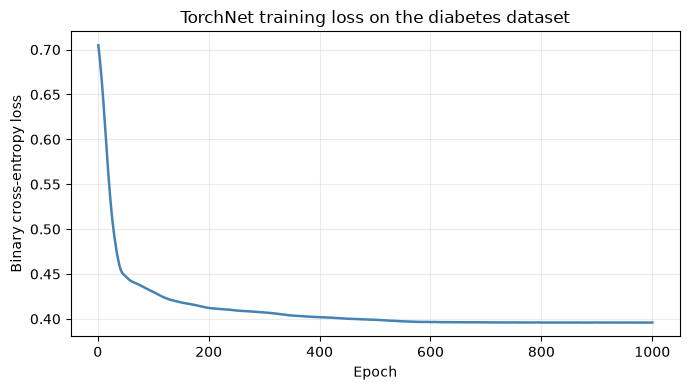

In [25]:
model.plot_loss(loss_history)

### 5. Saving the trained model

I saved my trained `TorchNet` model in ONNX format. The file includes
the trained weights and the feature means and scales from Part 1, so I
can use the original measurements from Table 1 when making a prediction.

In [26]:
import onnx

model_file = "diabetes_torchnet.onnx"
model.save_onnx(model_file)
onnx.checker.check_model(model_file)

print(f"Saved model: {model_file}")
print("ONNX model check passed.")

Saved model: diabetes_torchnet.onnx
ONNX model check passed.


### 6. Prediction for the sample in Table 1

I entered the eight measurements from Table 1 in the same order used
during training. I then loaded the saved ONNX model and used it to
predict the outcome for this sample.

In [27]:
table1_sample = pd.DataFrame(
    [[7, 149, 73, 94, 94, 32, 0.672, 45]],
    columns=feature_names,
)

sample_features = table1_sample.to_numpy(dtype=np.float32)
prediction = TorchNet.predict_onnx(model_file, sample_features)

display(table1_sample)
print(f"Predicted Outcome = {prediction.item()}")

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,7,149,73,94,94,32,0.672,45


Predicted Outcome = 1


For the sample in Table 1, my saved ONNX model predicted Outcome = 1,
which is the diabetes-positive class in this dataset.



I implemented `TorchNet` in `neuralnet.py` and
imported it in Part 1 using `from tornadochildd.model.neuralnet import TorchNet`.
Parts 1–6 show how I used the imported class to standardize the data,
display the network, train it, plot the loss, save the ONNX model, and
predict the outcome for the sample in Table 1.